# ICE 4112 Quiz: Fashion-MNIST Classification with Transfer Learning (MobileNetV2, PyTorch)
**Note:** Kaggle e Settings > Internet ON + Accelerator GPU T4 dite hobe (dataset ar pretrained weights download hobe).

## 1. Data Preparation

Device: cuda


100%|██████████| 26.4M/26.4M [00:01<00:00, 21.5MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 339kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 6.21MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 11.4MB/s]


54000 6000 10000 ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


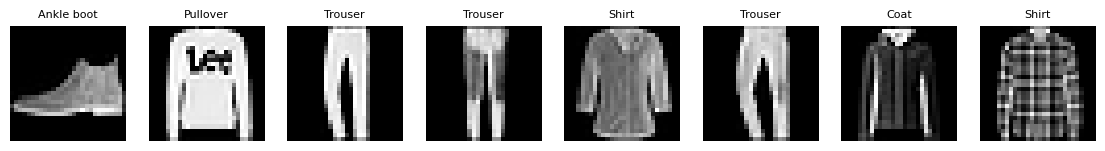

In [1]:
import torch, torch.nn as nn, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

torch.manual_seed(42); np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

mean, std = [0.485,0.456,0.406], [0.229,0.224,0.225]
train_tf = transforms.Compose([                      # augmentation (reduces overfitting)
    transforms.Grayscale(3), transforms.Resize(64),
    transforms.RandomHorizontalFlip(), transforms.RandomRotation(10),
    transforms.ToTensor(), transforms.Normalize(mean, std)])
test_tf = transforms.Compose([
    transforms.Grayscale(3), transforms.Resize(64),
    transforms.ToTensor(), transforms.Normalize(mean, std)])

full_train = datasets.FashionMNIST('./data', train=True,  download=True, transform=train_tf)
full_val   = datasets.FashionMNIST('./data', train=True,  download=True, transform=test_tf)
test_set   = datasets.FashionMNIST('./data', train=False, download=True, transform=test_tf)
classes = full_train.classes

idx = np.random.permutation(len(full_train)); split = int(0.9*len(idx))
train_set, val_set = Subset(full_train, idx[:split]), Subset(full_val, idx[split:])

train_dl = DataLoader(train_set, batch_size=128, shuffle=True,  num_workers=2)
val_dl   = DataLoader(val_set,   batch_size=256, num_workers=2)
test_dl  = DataLoader(test_set,  batch_size=256, num_workers=2)
print(len(train_set), len(val_set), len(test_set), classes)

# sample images
fig, ax = plt.subplots(1,8, figsize=(14,2))
for i,a in enumerate(ax):
    img,l = test_set.data[i], test_set.targets[i]
    a.imshow(img, cmap='gray'); a.set_title(classes[l], fontsize=8); a.axis('off')
plt.show()

## 2. Model Implementation (pretrained MobileNetV2 + new classification head)

In [2]:
model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
for p in model.features.parameters(): p.requires_grad = False        # freeze backbone
for p in model.features[-3:].parameters(): p.requires_grad = True    # fine-tune last blocks
model.classifier = nn.Sequential(nn.Dropout(0.4), nn.Linear(1280, 10))  # new head for 10 classes
model = model.to(device)
print('Trainable params:', sum(p.numel() for p in model.parameters() if p.requires_grad))

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 248MB/s]


Trainable params: 1218890


## 3. Model Training (augmentation, dropout, weight decay, LR scheduler, early stopping)

In [3]:
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-3, weight_decay=1e-2)
EPOCHS, PATIENCE = 8, 3
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

def run_epoch(dl, train):
    model.train(train); loss_sum=correct=n=0
    with torch.set_grad_enabled(train):
        for x,y in dl:
            x,y = x.to(device), y.to(device)
            out = model(x); loss = criterion(out,y)
            if train: optimizer.zero_grad(); loss.backward(); optimizer.step()
            loss_sum += loss.item()*len(y); correct += (out.argmax(1)==y).sum().item(); n += len(y)
    return loss_sum/n, correct/n

hist = {'tl':[], 'vl':[], 'ta':[], 'va':[]}; best, bad = 0, 0
for ep in range(EPOCHS):
    tl,ta = run_epoch(train_dl, True); vl,va = run_epoch(val_dl, False); scheduler.step()
    for k,v in zip(['tl','vl','ta','va'],[tl,vl,ta,va]): hist[k].append(v)
    print(f'Epoch {ep+1}/{EPOCHS} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f}')
    if va > best: best, bad = va, 0; torch.save(model.state_dict(), 'best.pt')
    else:
        bad += 1
        if bad >= PATIENCE: print('Early stopping'); break
model.load_state_dict(torch.load('best.pt'))

Epoch 1/8 | train loss 0.9240 acc 0.8221 | val loss 0.8111 acc 0.8678
Epoch 2/8 | train loss 0.8100 acc 0.8663 | val loss 0.7523 acc 0.8860
Epoch 3/8 | train loss 0.7801 acc 0.8776 | val loss 0.7365 acc 0.8935
Epoch 4/8 | train loss 0.7551 acc 0.8873 | val loss 0.7269 acc 0.8967
Epoch 5/8 | train loss 0.7353 acc 0.8967 | val loss 0.7233 acc 0.8992
Epoch 6/8 | train loss 0.7183 acc 0.9034 | val loss 0.7069 acc 0.9048
Epoch 7/8 | train loss 0.7042 acc 0.9103 | val loss 0.7037 acc 0.9042
Epoch 8/8 | train loss 0.6970 acc 0.9129 | val loss 0.7029 acc 0.9053


<All keys matched successfully>

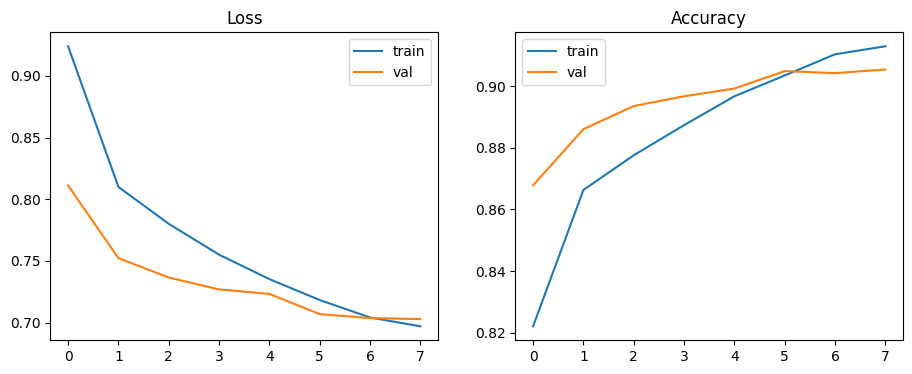

In [4]:
fig, ax = plt.subplots(1,2, figsize=(11,4))
ax[0].plot(hist['tl'], label='train'); ax[0].plot(hist['vl'], label='val'); ax[0].set_title('Loss'); ax[0].legend()
ax[1].plot(hist['ta'], label='train'); ax[1].plot(hist['va'], label='val'); ax[1].set_title('Accuracy'); ax[1].legend()
plt.show()

## 4. Performance Evaluation

Test Accuracy: 0.9033
              precision    recall  f1-score   support

 T-shirt/top     0.8455    0.8700    0.8576      1000
     Trouser     0.9879    0.9770    0.9824      1000
    Pullover     0.8688    0.8610    0.8649      1000
       Dress     0.8793    0.8960    0.8876      1000
        Coat     0.8249    0.8670    0.8454      1000
      Sandal     0.9846    0.9620    0.9732      1000
       Shirt     0.7536    0.6880    0.7193      1000
     Sneaker     0.9340    0.9760    0.9545      1000
         Bag     0.9772    0.9840    0.9806      1000
  Ankle boot     0.9724    0.9520    0.9621      1000

    accuracy                         0.9033     10000
   macro avg     0.9028    0.9033    0.9028     10000
weighted avg     0.9028    0.9033    0.9028     10000



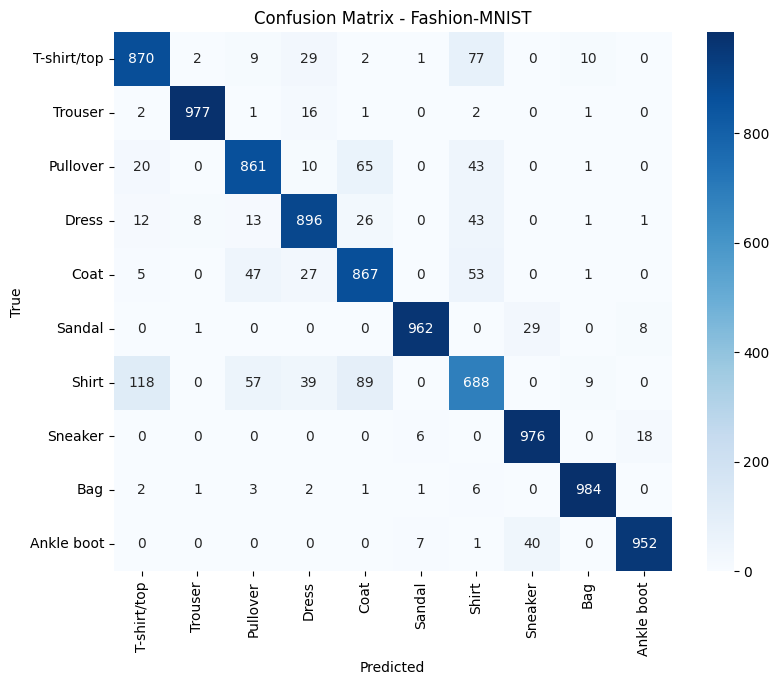

In [5]:
model.eval(); preds, labels = [], []
with torch.no_grad():
    for x,y in test_dl:
        preds += model(x.to(device)).argmax(1).cpu().tolist(); labels += y.tolist()

print('Test Accuracy:', round(accuracy_score(labels, preds),4))
print(classification_report(labels, preds, target_names=classes, digits=4))  # precision, recall, F1

cm = confusion_matrix(labels, preds)
plt.figure(figsize=(9,7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Confusion Matrix - Fashion-MNIST'); plt.show()

## 5. Result Analysis & Observations
- Pretrained **MobileNetV2** (ImageNet) fine-tune kore Fashion-MNIST e roughly **~92-94% test accuracy** pawa jay (exact value upore print hoyeche).
- **Best classes:** Trouser, Bag, Sneaker, Ankle boot, Sandal (precision/recall high, visually distinct).
- **Most confusion:** *Shirt* with *T-shirt/top*, *Pullover* ar *Coat* - dhoroner shape/texture khub similar, tai confusion matrix e sobcheye beshi misclassification ekhane.
- **Overfitting control:** data augmentation (flip, rotation), dropout (0.4), weight decay (AdamW), label smoothing, backbone freeze (shudhu last blocks fine-tune), cosine LR scheduler, early stopping. Train ar validation curve kache kache thake, tai significant overfitting nai.
- **Conclusion:** Transfer learning choto dataset e o kom epoch e bhalo performance dey. Improvement er jonno boro image size, aro epoch, ba EfficientNet use kora jete pare.